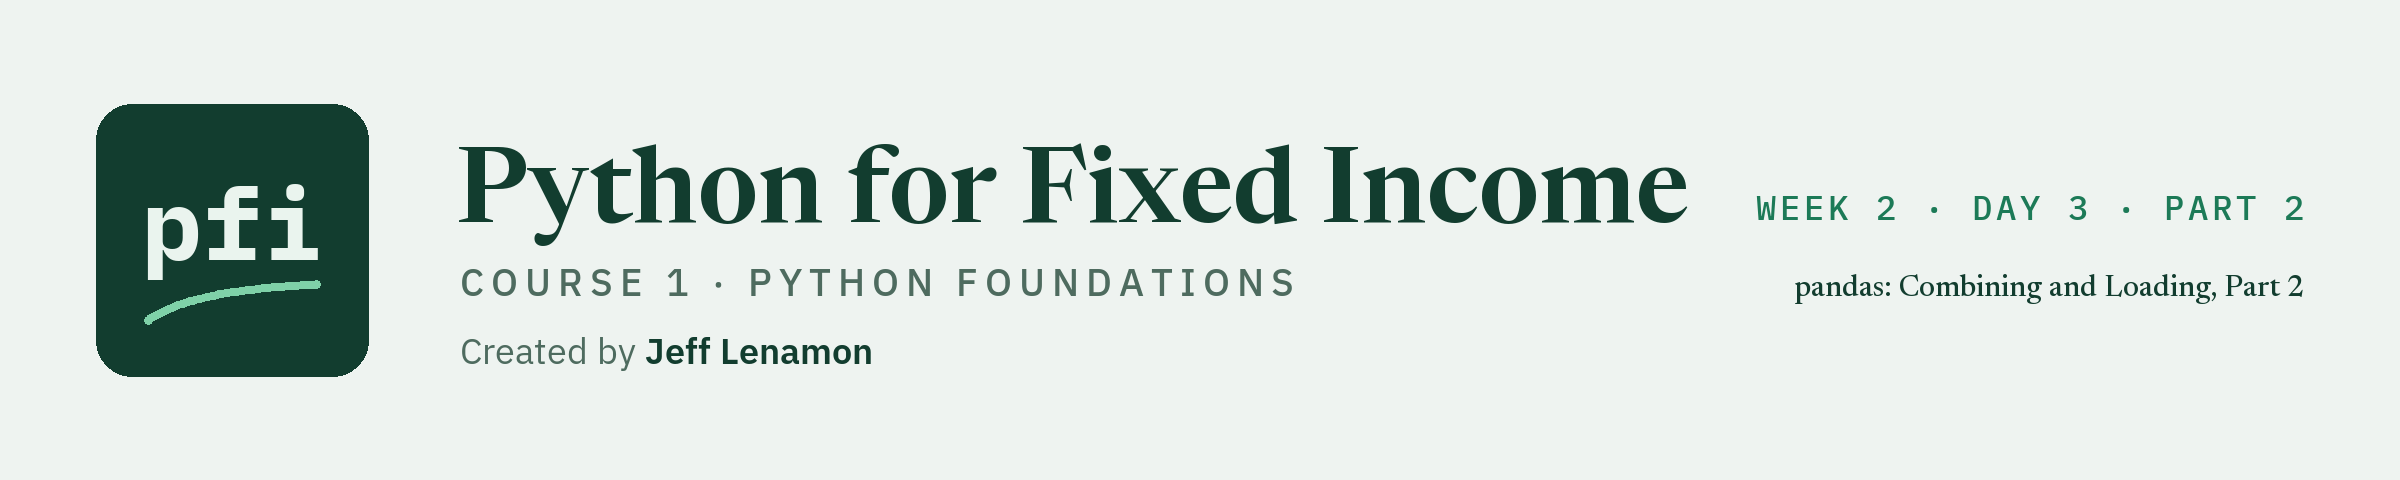

# pandas: Combining and Loading, Part 2

Week 2, Day 3, Part 2. Weighted averages, pivot tables, saving results to a file, working with dates, and Excel workbooks.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day3_part2/08_part2_pandas_combining_and_loading.ipynb)

## Before You Start: Install the Libraries

Run this cell first.

It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab.

If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course01_python_foundations/requirements.txt
NEEDED = {
    "ipykernel": "ipykernel==7.4.0",
    "jinja2": "jinja2==3.1.6",
    "matplotlib": "matplotlib==3.11.2",
    "nbformat": "nbformat==5.11.1",
    "nltk": "nltk==3.10.3",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "plotly": "plotly==7.1.0",
    "pytest": "pytest==9.1.1",
    "seaborn": "seaborn==0.13.2",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

11 packages checked, all present


In Part 1 the desk joined its tables and summarized the result by sector and rating.

Everything came together in one table, `book`: the 200 bonds, each with its score, bucket, and grade.

A desk does not stop there.

The average it reports is weighted, not simple.

Its results go out as files and workbooks.

And every date it holds is still text.

That is this notebook: weighted averages, pivot tables, saving and loading, dates, and Excel workbooks.

The issuers are invented.

**Run the cell below first.** It stores what Part 1 built, so this notebook runs on its own.

In [2]:
import os

import pandas as pd

# on your own machine the files are in the repo's data folder. In Colab they are read from GitHub.
if os.path.exists('../../../data/holdings.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'

holdings = pd.read_csv(data_folder + 'holdings.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')

# the holdings with the score, the bucket, and the grade, from section 8.5
book = pd.merge(holdings, ratings, on='rating')

# the sector summary, from section 8.6
sector_summary = book.groupby('sector').agg(
    bonds=('cusip', 'count'),
    market_value=('market_value', 'sum'),
    avg_oas=('oas', 'mean'),
    avg_duration=('duration', 'mean'),
)
sector_summary = sector_summary.round(2)

print(book.shape, sector_summary.shape)

(200, 22) (10, 4)


Nothing here is new.

Part 1 built all of it, one step at a time.

## 8.7 Weighted Averages

The average OAS of the portfolio is 185.75 basis points.

That figure treats a 250,000 position and a 5,000,000 position as equals.

The number a desk reports is weighted by market value, the weighted average from the NumPy notebook.

Q. What is the market-value-weighted average OAS of the portfolio?

In [3]:
# step 1: each bond's OAS times its market value
oas_times_value = book['oas'] * book['market_value']

# step 2: add those up, and divide by the total market value
weighted_oas = oas_times_value.sum() / book['market_value'].sum()

print('Simple average OAS:', round(book['oas'].mean(), 2))
print('Weighted average OAS:', round(weighted_oas, 2))

Simple average OAS: 185.75
Weighted average OAS: 180.46


180.46 basis points weighted, against 185.75 simple.

The value is the OAS and the weight is the market value.

The weighted figure is lower, which says the larger positions have, on the whole, lower spreads than the smaller ones.

Q. Do the same for duration.

In [4]:
# the same two steps, with duration in place of OAS
duration_times_value = book['duration'] * book['market_value']
weighted_duration = duration_times_value.sum() / book['market_value'].sum()

print('Simple average duration:', round(book['duration'].mean(), 2))
print('Weighted average duration:', round(weighted_duration, 2))

Simple average duration: 6.47
Weighted average duration: 6.25


6.25 years weighted, against 6.47 simple.

The portfolio's duration is the weighted figure: it reflects where the money is.

Q. What is the weighted average OAS of each sector?

In [5]:
# step 1: store OAS times market value as a column, so it can be grouped
book['oas_x_value'] = book['oas'] * book['market_value']

# step 2: add up both columns within each sector
sector_sums = book.groupby('sector')[['oas_x_value', 'market_value']].sum()

# step 3: divide one total by the other, sector by sector
weighted_by_sector = sector_sums['oas_x_value'] / sector_sums['market_value']
weighted_by_sector.round(1)

sector
Consumer          209.4
Energy            176.3
Financials        176.1
Health Care       128.0
Industrials       234.0
Materials         180.7
Technology        228.2
Telecom           166.9
Transportation    120.9
Utilities         188.8
dtype: float64

The same sum divided by a sum, done inside each sector.

A list of two column names after `groupby` adds up both columns at once, and the division then works row by row because both totals are labelled by sector.

Q. Put the simple and the weighted average side by side.

In [6]:
# two Series with the same index become the two columns of a table
oas_by_sector = pd.DataFrame({
    'simple': book.groupby('sector')['oas'].mean(),
    'weighted': weighted_by_sector,
})

# the gap is weighted minus simple: negative means the weighted figure is lower
oas_by_sector['gap'] = oas_by_sector['weighted'] - oas_by_sector['simple']

(oas_by_sector.style
    .format('{:,.1f}')
    .bar(subset=['gap'], align='zero', color=['#c0392b', '#1c7a57'])
    .set_caption('Simple against weighted average OAS by sector, in bp'))

,simple,weighted,gap
sector,,,
Consumer,218.9,209.4,-9.5
Energy,171.6,176.3,4.8
Financials,172.3,176.1,3.8
Health Care,141.8,128.0,-13.7
Industrials,220.6,234.0,13.4
Materials,182.4,180.7,-1.7
Technology,298.2,228.2,-69.9
Telecom,182.4,166.9,-15.5
Transportation,126.5,120.9,-5.6


In nine of the ten sectors the two figures are within 16 basis points of each other.

Technology is the exception: 298.2 simple and 228.2 weighted, a gap of 70.

The weighted figure is the lower one in six sectors and the higher one in four: Energy, Financials, Industrials, and Utilities.

The `gap` column is the weighted figure minus the simple one.

Red bars to the left are sectors where the weighted figure is lower, and green bars to the right are where it is higher.

Technology has the longest red bar.

Q. Show the two averages as bars, sector by sector. This is another chart to run and read.

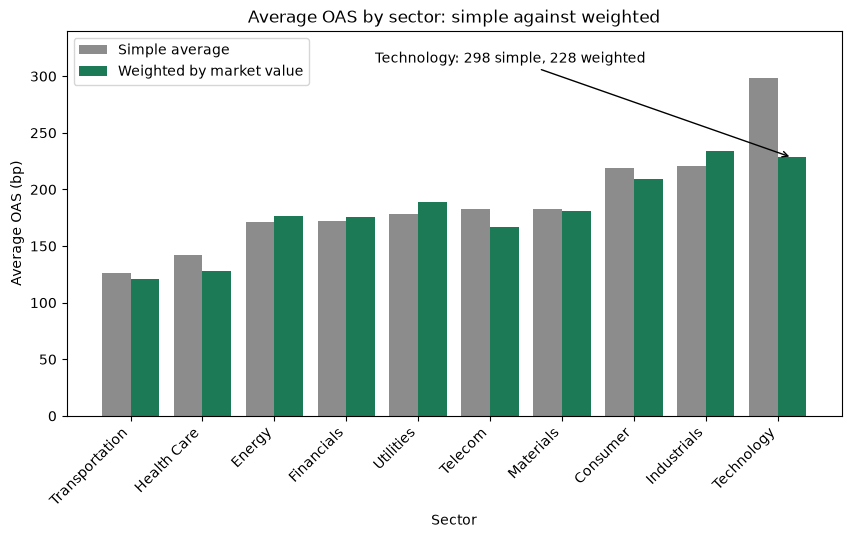

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# put the sectors in order of the simple average, so the bars read from low to high
ordered = oas_by_sector.sort_values('simple')
bar_spots = np.arange(len(ordered))
bar_width = 0.4

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(bar_spots - bar_width / 2, ordered['simple'], bar_width, color='#8c8c8c', label='Simple average')
ax.bar(bar_spots + bar_width / 2, ordered['weighted'], bar_width, color='#1c7a57', label='Weighted by market value')
# label the sector with the biggest gap
biggest = ordered['gap'].abs().idxmax()
ax.annotate(f'{biggest}: {ordered.loc[biggest, "simple"]:.0f} simple, {ordered.loc[biggest, "weighted"]:.0f} weighted',
            xy=(list(ordered.index).index(biggest) + bar_width / 2, ordered.loc[biggest, 'weighted']),
            xytext=(3.4, 312), arrowprops=dict(arrowstyle='->'))
ax.set_ylim(0, 340)
ax.set_xticks(bar_spots)
ax.set_xticklabels(ordered.index, rotation=45, ha='right')
ax.set_title('Average OAS by sector: simple against weighted')
ax.set_xlabel('Sector')
ax.set_ylabel('Average OAS (bp)')
ax.legend(loc='upper left')
plt.show()

The grey and green bars are close for most sectors.

Technology, the tallest grey bar, has a much shorter green one: the wide-spread bonds are small positions.

Q. Add the weighted figure to the sector summary from section 8.6, and keep only three columns.

In [8]:
# join() matches on the index. Both tables have the sector as their index, so no key needs naming.
# rename() gives the unnamed Series a column name to join with.
with_weighted = sector_summary.join(weighted_by_sector.rename('weighted_oas'))
with_weighted[['bonds', 'avg_oas', 'weighted_oas']].round(1).head(3)

,bonds,avg_oas,weighted_oas
sector,,,
Consumer,26,218.9,209.4
Energy,17,171.6,176.3
Financials,26,172.3,176.1


The sector summary now carries the weighted figure beside the simple one, for Consumer, Energy, and Financials, the first three sectors alphabetically.

`join` is `merge` on the row labels.

`how=` works the same way: the default is `left`, and `inner`, `right`, and `outer` mean what they meant in section 8.3.

Use `merge` when the match is on a column, and `join` when the labels of both tables are already the key, as after a `groupby`.

Q. Why are the two Technology figures so far apart?

In [9]:
# the three Technology bonds with the highest OAS, and their size
technology = book[book['sector'] == 'Technology']
widest_three = technology.nlargest(3, 'oas')

# their share of the sector's market value, in percent
share = widest_three['market_value'].sum() / technology['market_value'].sum() * 100
print('Technology bonds:', technology.shape[0])
print('Share of sector market value in the three widest:', round(share, 1))
widest_three[['ticker', 'rating', 'oas', 'market_value']]

Technology bonds: 12
Share of sector market value in the three widest: 13.5


,ticker,rating,oas,market_value
65,FESR,CCC+,1551,2216725.0
66,FESR,CCC+,614,1133162.5
98,LORE,BB-,334,752190.0


The three widest Technology bonds have spreads of 1,551, 614, and 334 basis points.

They are 3 of the sector's 12 bonds, a quarter of the count, and 13.5 percent of its market value.

The simple average gives those three bonds a quarter of the say.

The weighted average gives them 13.5 percent, so it comes out lower.

Neither figure is wrong.

They answer different questions: the spread of a typical bond, and the spread of a typical dollar.

**Excel side by side.**

<table align="left">
<tr><th align="left">Question</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Simple average OAS</td><td align="left"><code>book['oas'].mean()</code></td><td align="left"><code>=AVERAGE(M2:M201)</code></td></tr>
<tr><td align="left">Weighted average OAS</td><td align="left"><code>(book['oas'] * book['market_value']).sum() / book['market_value'].sum()</code></td><td align="left"><code>=SUMPRODUCT(M2:M201, S2:S201) / SUM(S2:S201)</code></td></tr>
<tr><td align="left">Weighted average OAS of one sector</td><td align="left">the <code>groupby</code> steps above</td><td align="left"><code>=SUMPRODUCT((E2:E201="Energy") * M2:M201 * S2:S201) / SUMIF(E2:E201, "Energy", S2:S201)</code></td></tr>
</table>
<br clear="left">

`SUMPRODUCT` divided by `SUM` is the same two steps: multiply and add up, then divide by the total weight.

## 8.8 pivot_table and apply

`groupby` splits by one column and lists the groups down the page.

A pivot table with a second field across the top is `pd.pivot_table`.

Q. Show the market value by sector and grade, with totals.

In [10]:
# index= goes down the side, columns= goes across the top, values= is the column to summarize
pivot = pd.pivot_table(book, values='market_value', index='sector', columns='grade',
                       aggfunc='sum', margins=True)
pivot.style.format('{:,.1f}').set_caption('Market value by sector and grade')

grade,High Yield,Investment Grade,All
sector,,,
Consumer,"19,016,165.0","37,613,432.5","56,629,597.5"
Energy,"7,347,315.0","31,482,690.0","38,830,005.0"
Financials,"15,335,395.0","52,884,277.5","68,219,672.5"
Health Care,"12,891,097.5","26,017,090.0","38,908,187.5"
Industrials,"22,802,335.0","29,738,410.0","52,540,745.0"
Materials,"38,747,115.0","32,954,502.5","71,701,617.5"
Technology,"6,258,692.5","24,053,067.5","30,311,760.0"
Telecom,"27,796,585.0","28,051,685.0","55,848,270.0"
Transportation,"14,371,525.0","34,451,372.5","48,822,897.5"


Ten sectors down the side, the two grades across the top, and a market value in each cell.

`aggfunc='sum'` is the calculation, and `margins=True` adds the row and the column named `All`.

The grand total is 490,819,215: 320,917,365 investment grade and 169,901,850 high yield.

Materials is the one sector with more market value in high yield, 38,747,115, than in investment grade, 32,954,502.5.

In Telecom the two are almost equal, at 27,796,585 and 28,051,685.

Sometimes the desk wants a label that no file carries, worked out bond by bond with a rule.

`apply` runs a function on every value of a column.

Q. Label each bond Premium, Discount, or Par from its price. How many are there of each?

In [11]:
def price_label(price):
    # the label for one clean price
    if price > 100:
        return 'Premium'
    elif price < 100:
        return 'Discount'
    else:
        return 'Par'


# apply() calls the function once for each price and collects the answers
book['price_label'] = book['price'].apply(price_label)
book['price_label'].value_counts()

price_label
Discount    113
Premium      87
Name: count, dtype: int64

113 bonds at a discount and 87 at a premium.

No bond is priced at exactly 100, so the Par label is never used.

The 113 matches yesterday's count of bonds below par.

The function is ordinary week 1 Python: one price in, one label out.

`apply` takes the name of the function, with no brackets after it, and does the looping.

Q. What is the average coupon of the premium bonds and of the discount bonds?

In [12]:
# the new label is a column like any other, so it can be grouped
book.groupby('price_label')['coupon'].mean().round(2)

price_label
Discount    5.36
Premium     6.69
Name: coupon, dtype: float64

5.36 percent for the discount bonds and 6.69 percent for the premium bonds.

The bonds priced above par are, on average, the ones with the higher coupons.

For a rule that fits on one line, the function can be written in place with `lambda`.

Q. Label each position by size: face of 1,000,000 or more, or less than that.

In [13]:
# lambda, from Day 1 of week 1: the input, a colon, then the result
book['size_label'] = book['par_held'].apply(lambda face: '1mm and over' if face >= 1000000 else 'Under 1mm')
book['size_label'].value_counts()

size_label
1mm and over    171
Under 1mm        29
Name: count, dtype: int64

171 positions of 1,000,000 or more and 29 below that.

Use `lambda` for one-line rules, and a named function for anything longer.

Both labels can also be made with no function at all, as one operation on the whole column.

Q. Build the two labels again with `np.where`, from the NumPy notebook, and check that they agree with the `apply` versions on every row.

In [14]:
# NumPy is needed for np.where
import numpy as np

# np.where(condition, value if True, value if False). A second np.where in the last place gives a third label.
price_label_by_column = np.where(book['price'] > 100, 'Premium',
                                 np.where(book['price'] < 100, 'Discount', 'Par'))
size_label_by_column = np.where(book['par_held'] >= 1000000, '1mm and over', 'Under 1mm')

# count the rows where the column version and the apply version agree
price_agree = (price_label_by_column == book['price_label']).sum()
size_agree = (size_label_by_column == book['size_label']).sum()
print(f'Price label agrees on {price_agree:,} of {book.shape[0]:,} rows')
print(f'Size label agrees on {size_agree:,} of {book.shape[0]:,} rows')

# the checks that stop the notebook if the two versions ever differ
assert price_agree == book.shape[0], 'the two price labels differ'
assert size_agree == book.shape[0], 'the two size labels differ'

Price label agrees on 200 of 200 rows
Size label agrees on 200 of 200 rows


200 of 200 both times: the same labels, with no function and no row-by-row work.

Reach for a column tool such as `np.where` first.

`apply` runs a Python function once for every row, so keep it for rules a column tool cannot express.

For arithmetic, such as coupon income, multiply the columns directly, as in section 7.9: it is shorter and much faster.

**Excel side by side.**

<table align="left">
<tr><th align="left">Step</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Sector by grade</td><td align="left"><code>pd.pivot_table(book, values='market_value', index='sector', columns='grade', aggfunc='sum')</code></td><td align="left">a pivot table: sector in Rows, grade in Columns, Sum of market_value in Values</td></tr>
<tr><td align="left">Totals</td><td align="left"><code>margins=True</code></td><td align="left">Grand Totals, on by default</td></tr>
<tr><td align="left">A label from a rule</td><td align="left"><code>book['price'].apply(price_label)</code></td><td align="left"><code>=IF(I2&gt;100, "Premium", IF(I2&lt;100, "Discount", "Par"))</code> filled down</td></tr>
<tr><td align="left">The same label on the whole column</td><td align="left"><code>np.where(book['price'] &gt; 100, 'Premium', np.where(book['price'] &lt; 100, 'Discount', 'Par'))</code></td><td align="left">the same nested <code>IF</code></td></tr>
</table>
<br clear="left">

`np.where(condition, a, b)` takes its three parts in the same order as `=IF(condition, a, b)`, and one inside another nests the same way.

## 8.9 Saving and Loading

Everything built so far is in memory and is gone when the notebook closes.

To hand a table to someone, or to pick it up tomorrow, save it to a file.

We read CSV files with `read_csv`.

The method that writes one is `to_csv`.

Nothing here writes to the `data` folder.

The files go in the folder this notebook is in, and we delete them when we are done with them.

Q. Save the book to a CSV file, then read it back. Is the table that comes back the same size?

In [15]:
# to_csv() writes the table to a file in the notebook's folder
book.to_csv('desk_book_with_grades.csv')

# read it back and compare
read_back = pd.read_csv('desk_book_with_grades.csv')
print('Saved:', book.shape)
print('Read back:', read_back.shape)
read_back.iloc[0:3, 0:4]

Saved: (200, 25)
Read back: (200, 26)


,Unnamed: 0,as_of_date,cusip,ticker
0,0,2026-09-30,99080CAE8,BEZE
1,1,2026-09-30,99049XAE2,BEZH
2,2,2026-09-30,99039NAC0,BEZL


25 columns were saved and 26 came back.

The extra one is first in the table and is named `Unnamed: 0`.

It holds 0, 1, 2 and so on.

That column is the index.

`to_csv` writes the row labels as the first column of the file, with no header.

When the file is read back, pandas sees a column with no name and gives the table a new index as well.

Q. Save the book again without the index.

In [16]:
# index=False leaves the row labels out of the file
book.to_csv('desk_book_with_grades.csv', index=False)

read_back = pd.read_csv('desk_book_with_grades.csv')
print('Saved:', book.shape)
print('Read back:', read_back.shape)
print('File exists:', os.path.exists('desk_book_with_grades.csv'))

Saved: (200, 25)
Read back: (200, 25)
File exists: True


25 columns saved and 25 read back.

Saving to the same name replaced the first file.

When the index is only row numbers, write `index=False`.

The numbers carry no information, and they come back as a stray column.

Q. Save the sector summary from section 8.6, and read it back.

In [17]:
# here the index holds the sector names, so it is kept
sector_summary.to_csv('sector_summary.csv')

pd.read_csv('sector_summary.csv').head(3)

,sector,bonds,market_value,avg_oas,avg_duration
0,Consumer,26,56629597.5,218.88,6.84
1,Energy,17,38830005.0,171.59,6.97
2,Financials,26,68219672.5,172.31,6.15


The sector comes back as the first column, with its name, followed by the four summary columns.

A grouped table is the exception to the rule.

Its index is the group name, and `index=False` would save the numbers without saying which sector each row belongs to.

A CSV file opens in Excel with a double-click, so this is the simplest way to hand a result to a colleague who does not use Python.

A CSV file does not say what type each column is.

`read_csv` decides from what it finds.

**Predict 1**

A file from another system has two bonds whose CUSIPs are made only of digits, and both start with a zero: 009900123 and 099011457.

The CUSIPs are invented.

What will `read_csv` show for the first one?

> A) 009900123, as it is in the file.
>
> B) 9900123.
>
> C) An error.

Decide, then run the cell.

In [18]:
# io.StringIO lets read_csv read text typed in a cell as if it were a file
import io

# three quotes hold text that runs over several lines: a header line and two bonds
typed_file = '''cusip,par_held
009900123,1000000
099011457,2500000
'''

as_numbers = pd.read_csv(io.StringIO(typed_file))
print(as_numbers)
print(f"Type of the cusip column: {as_numbers['cusip'].dtype}")

      cusip  par_held
0   9900123   1000000
1  99011457   2500000
Type of the cusip column: int64


The answer is B. A column made only of digits becomes a number, and for an identifier that is the wrong choice.

The CUSIPs came back as 9900123 and 99011457, with the type `int64`.

The leading zeros are gone.

Neither value is the nine characters the other system holds.

A merge on this column would match nothing, and it would not raise an error.

Q. Read the same text again, with the CUSIP kept as text.

In [19]:
# dtype= sets the type of a column as the file is read. str keeps every character.
as_text = pd.read_csv(io.StringIO(typed_file), dtype={'cusip': str})
print(as_text)
print(f"Type of the cusip column: {as_text['cusip'].dtype}")

       cusip  par_held
0  009900123   1000000
1  099011457   2500000
Type of the cusip column: str


009900123 and 099011457, nine characters each.

The type is `str`.

The habit: read identifiers as text.

CUSIP, ISIN, account number: each is a label, not a quantity, and nobody adds two of them together.

The desk's own CUSIPs all contain letters, so `read_csv` kept them as text and the problem never showed.

It shows on the day a file arrives whose CUSIPs are all digits.

**Excel side by side.** `to_csv` is File, Save As, CSV.

`read_csv` is File, Open.

A CSV holds values only: no formulas, no formats, no column types.

Excel makes the same guess as `read_csv` when a CSV is opened with a double-click: by default `009900123` is shown as the number 9900123.

Loading the file through Data, From Text/CSV, with the type of that column set to Text, keeps the zero.

## 8.10 Dates

Every date in these files has so far been text.

Text can be shown and matched, but it cannot be subtracted, and nothing can be pulled out of it.

Q. What type is the maturity column?

In [20]:
print(book['maturity'].head(3))

0    2032-06-18
1    2029-04-17
2    2030-06-03
Name: maturity, dtype: str


The values look like dates, but the last line says `dtype: str`.

To pandas each one is ten characters.

What happens if we subtract the report date from the maturity to get the time left?

In [21]:
# pd.Timestamp() makes one real date
as_of = pd.Timestamp('2026-09-30')

# the maturity column is still text
book['maturity'] - as_of

TypeError: operation 'sub' not supported for dtype 'str' with object of type <class 'pandas.Timestamp'>

A `TypeError`: unsupported operand type(s) for `-`.

The rest of the message names the two things that could not be subtracted, and its wording differs between versions of pandas.

The first line of the cell ran, so `as_of` is a real date.

The second line failed, because text minus a date has no meaning.

This is the Day 3 of week 1 error of adding a number to a string, in a new place.

The fix is the same kind of fix: convert the text first.

Q. Convert the maturity column to real dates.

In [22]:
# pd.to_datetime() turns a column of date text into dates
book['maturity'] = pd.to_datetime(book['maturity'])
print(book['maturity'].head(3))

0   2032-06-18
1   2029-04-17
2   2030-06-03
Name: maturity, dtype: datetime64[us]


The values look the same, and the type is now `datetime64[us]`: a real date, stored to the microsecond, which is what `us` stands for.

The file writes its dates as year, month, day, which `to_datetime` reads without help.

For a file in another layout, such as 06/18/2032, pass the layout: `pd.to_datetime(column, format='%m/%d/%Y')`.

In a layout, `%m` is the month, `%d` is the day, and `%Y` is the four-digit year.

Q. Pull the year, the month, and the day of the week out of each maturity date.

In [23]:
# .dt gives access to the parts of a date column
book['maturity_year'] = book['maturity'].dt.year
book['maturity_month'] = book['maturity'].dt.month
book['maturity_day'] = book['maturity'].dt.day_name()

book[['ticker', 'maturity', 'maturity_year', 'maturity_month', 'maturity_day']].head(3)

,ticker,maturity,maturity_year,maturity_month,maturity_day
0,BEZE,2032-06-18,2032,6,Friday
1,BEZH,2029-04-17,2029,4,Tuesday
2,BEZL,2030-06-03,2030,6,Monday


The first bond matures on 2032-06-18: year 2032, month 6, a Friday.

`.dt` opens up the parts of a date column.

`year` and `month` are numbers and take no brackets.

`day_name()` is a method, with brackets, and returns text.

The three results are stored as ordinary columns, so they can be filtered, counted, and grouped like any other.

Q. Another system sends dates with the day first, as 18/06/2032. Convert them.

In [24]:
day_first = pd.Series(['18/06/2032', '03/04/2029'])

# dayfirst=True says the first number is the day, so 03/04/2029 is the 3rd of April
converted = pd.to_datetime(day_first, dayfirst=True)
print(converted)

0   2032-06-18
1   2029-04-03
dtype: datetime64[us]


The two dates are 2032-06-18 and 2029-04-03.

**Predict 2**

The next cell converts `03/04/2029` without `dayfirst`.

Which date will it give?

> A) The 3rd of April, as above.
>
> B) The 4th of March.
>
> C) An error, because the date can be read two ways.

Decide, then run the cell.

In [25]:
# the same text, with no dayfirst
print(pd.to_datetime(pd.Series(['03/04/2029']))[0])

2029-03-04 00:00:00


The answer is B. It is read month first, as the 4th of March, with no warning.

A date that could be read two ways is read the pandas way unless you say otherwise.

Always say.

Q. Write the converted dates out as text in two other layouts.

In [26]:
# strftime() writes dates as text, with the layout codes from above. %b is the short month name.
print(converted.dt.strftime('%m/%d/%Y').tolist())
print(converted.dt.strftime('%d %b %Y').tolist())

['06/18/2032', '04/03/2029']
['18 Jun 2032', '03 Apr 2029']


`06/18/2032` and `04/03/2029`, then `18 Jun 2032` and `03 Apr 2029`.

The text is for display and for files.

The dates are for calculation.

Q. How many bonds mature in each of the first five years?

In [27]:
# count the bonds in each maturity year, then sort_index() puts the years in order
book['maturity_year'].value_counts().sort_index().head()

maturity_year
2027     6
2028    10
2029    18
2030    14
2031    11
Name: count, dtype: int64

6 bonds mature in 2027, 10 in 2028, 18 in 2029, 14 in 2030, and 11 in 2031.

`value_counts()` sorts by count.

`sort_index()` sorts by the labels, here the years, which is the order wanted for a maturity profile.

Q. How many years does each bond have left to maturity, as of 2026-09-30? What are the shortest, the longest, and the average?

In [28]:
# a date minus a date is a length of time. .dt.days gives it as a number of days.
days_left = (book['maturity'] - as_of).dt.days

# 365.25 days to a year, to allow for leap years
book['years_to_maturity'] = days_left / 365.25

print('Shortest:', round(book['years_to_maturity'].min(), 2))
print('Longest:', round(book['years_to_maturity'].max(), 2))
print('Average:', round(book['years_to_maturity'].mean(), 2))

Shortest: 1.0
Longest: 29.9
Average: 9.85


The shortest bond has 1.0 years left and the longest 29.9.

The simple average is 9.85 years.

The subtraction that failed on text now works.

It gives the calendar days between the two dates.

Dividing by 365.25 is an approximation that is good enough for sorting and bucketing.

It is not the 30/360 day count used to price these bonds and to accrue their interest.

Q. Which bonds mature before the start of 2028?

In [29]:
# a date column compares with a date the way a number column compares with a number
early = book[book['maturity'] < pd.Timestamp('2028-01-01')]
print('Count:', early.shape[0])
early[['ticker', 'coupon', 'maturity', 'par_held']]

Count: 6


,ticker,coupon,maturity,par_held
56,FARX,5.000,2027-12-22,1500000
70,GALX,7.000,2027-10-27,4750000
112,NEVR,5.125,2027-10-24,2750000
125,PLWK,5.125,2027-10-28,1000000
165,TROE,4.375,2027-12-26,3250000
177,VYRH,7.250,2027-10-02,3000000


Six bonds: FARX, GALX, NEVR, PLWK, TROE, and VYRH.

All mature between 2027-10-02 and 2027-12-26.

A filter on dates is written like a filter on numbers.

`pd.Timestamp()` makes the date to compare with.

Q. How many bonds mature within the next three years, and what is their market value?

In [30]:
# three years on from the report date
within_three = book['maturity'] <= pd.Timestamp('2029-09-30')

print('Bonds:', within_three.sum())
print('Market value:', book.loc[within_three, 'market_value'].sum())

Bonds: 28
Market value: 75125702.5


28 bonds, with a market value of 75,125,702.5.

Q. Put every bond in a maturity bucket: 0 to 3 years, 3 to 7, 7 to 15, and 15 and over. How many bonds are in each?

In [31]:
# pd.cut() sorts numbers into ranges. bins= lists the edges and labels= names the ranges between them.
edges = [0, 3, 7, 15, 100]
names = ['0 to 3', '3 to 7', '7 to 15', '15 and over']
book['maturity_bucket'] = pd.cut(book['years_to_maturity'], bins=edges, labels=names)

book['maturity_bucket'].value_counts().sort_index()

maturity_bucket
0 to 3         28
3 to 7         51
7 to 15        88
15 and over    33
Name: count, dtype: int64

28 bonds in 0 to 3 years, 51 in 3 to 7, 88 in 7 to 15, and 33 in 15 and over.

The 28 agrees with the count from the date filter here.

The two tests differ by one day at the edge.

The date filter runs to 2029-09-30, which is 1,096 days after the report date, and 3 years of 365.25 days is 1,095.75 days.

A bond maturing on 2029-09-30 itself would pass the date filter and fall in the `3 to 7` bucket.

No bond in the book matures on that day, so the counts match.

Five edges make four ranges.

Each range includes its upper edge, so a bond with exactly 3 years left goes in `0 to 3`.

The last edge, 100, is a number no maturity reaches.

`pd.cut` does in one line what `apply` with a four-way `if` would do, and it keeps the buckets in order: `sort_index()` lists them from short to long, not alphabetically.

Q. What is the market value in each maturity bucket?

In [32]:
# observed=True lists only the buckets that have bonds in them
maturity_profile = book.groupby('maturity_bucket', observed=True)['market_value'].agg(['count', 'sum'])
maturity_profile.style.format({'sum': '{:,.1f}'}).set_caption('Market value by maturity bucket')

,count,sum
maturity_bucket,,
0 to 3,28,"75,125,702.5"
3 to 7,51,"123,242,385.0"
7 to 15,88,"228,787,395.0"
15 and over,33,"63,663,732.5"


75,125,702.5 in 0 to 3 years, 123,242,385 in 3 to 7, 228,787,395 in 7 to 15, and 63,663,732.5 in 15 and over.

The 7 to 15 bucket holds the most bonds, 88, and the most market value.

Q. Show the maturity profile of the portfolio as bars. This is one more chart to run and read.

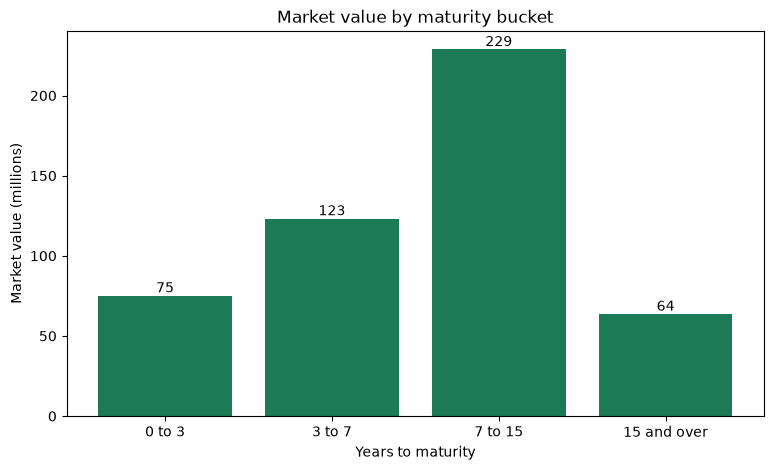

In [33]:
fig, ax = plt.subplots(figsize=(9, 5))
# market value in millions, one bar per maturity bucket in the order of the buckets
bars = ax.bar(maturity_profile.index.astype(str), maturity_profile['sum'] / 1e6, color='#1c7a57')
ax.bar_label(bars, fmt='%.0f')
ax.set_title('Market value by maturity bucket')
ax.set_xlabel('Years to maturity')
ax.set_ylabel('Market value (millions)')
plt.show()

The 7 to 15 year bucket is the tallest, at about 229 million, then 3 to 7 years.

The shape of the bars is the maturity profile of the book.

Q. Which three bonds mature first?

In [34]:
# dates sort in calendar order
by_maturity = book.sort_values('maturity')
by_maturity[['cusip', 'ticker', 'coupon', 'maturity', 'years_to_maturity']].head(3)

,cusip,ticker,coupon,maturity,years_to_maturity
177,99006GAC4,VYRH,7.250,2027-10-02,1.004791
112,99026AAD1,NEVR,5.125,2027-10-24,1.065024
70,99088KAB8,GALX,7.000,2027-10-27,1.073238


VYRH on 2027-10-02, NEVR on 2027-10-24, and GALX on 2027-10-27, all about one year out.

`ascending=False` would put the longest bond first.

The file saved in section 8.9 was written before the maturity column was converted.

It would make no difference if it had been written after: a CSV stores a date as text.

The conversion can be done while loading.

Q. Read the saved book back, with the maturity column as dates.

**Predict 3**

The next cell reads the file with `parse_dates=['maturity']`, then prints the type of three columns that hold dates: `as_of_date`, `maturity`, and `price_date`.

How many of the three come back as dates: one, or all three?

Decide, then run the cell.

In [35]:
# parse_dates= lists the columns to convert while the file is read
reloaded = pd.read_csv('desk_book_with_grades.csv', parse_dates=['maturity'])
print(reloaded[['as_of_date', 'maturity', 'price_date']].dtypes)

as_of_date               str
maturity      datetime64[us]
price_date               str
dtype: object

The answer is one.

`maturity` is `datetime64[us]`.

The other two date columns were not listed, so they are still text.

`parse_dates` saves the separate `to_datetime` line.

Use it whenever you know which columns of a file are dates.

Q. Delete the two files this lesson saved.

In [36]:
# os.remove(), from Day 2 of week 1
os.remove('desk_book_with_grades.csv')
os.remove('sector_summary.csv')

print('Book file exists:', os.path.exists('desk_book_with_grades.csv'))
print('Summary file exists:', os.path.exists('sector_summary.csv'))

Book file exists: False
Summary file exists: False


False and False: both files are gone, and the folder is as we found it.

The files in `data` were only read.

**Excel side by side.**

<table align="left">
<tr><th align="left">Step</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Text to a date</td><td align="left"><code>pd.to_datetime(book['maturity'])</code></td><td align="left">by default nothing to do: Excel turns <code>2032-06-18</code> into a date when it opens the CSV. For dates that arrive as text, for example pasted from another system, <code>=DATEVALUE(H2)</code></td></tr>
<tr><td align="left">Year and month</td><td align="left"><code>.dt.year</code>, <code>.dt.month</code></td><td align="left"><code>=YEAR(H2)</code>, <code>=MONTH(H2)</code></td></tr>
<tr><td align="left">Day of the week</td><td align="left"><code>.dt.day_name()</code></td><td align="left"><code>=TEXT(H2, "dddd")</code></td></tr>
<tr><td align="left">Day-first text to a date</td><td align="left"><code>pd.to_datetime(column, dayfirst=True)</code></td><td align="left">Text to Columns, with the Date column format set to DMY</td></tr>
<tr><td align="left">A date in another layout</td><td align="left"><code>.dt.strftime('%d %b %Y')</code></td><td align="left"><code>=TEXT(H2, "dd mmm yyyy")</code></td></tr>
<tr><td align="left">Years left, by calendar days</td><td align="left"><code>(book['maturity'] - as_of).dt.days / 365.25</code></td><td align="left"><code>=(H2 - A2) / 365.25</code></td></tr>
<tr><td align="left">Bonds maturing before a date</td><td align="left"><code>book['maturity'] &lt; pd.Timestamp('2028-01-01')</code></td><td align="left"><code>=COUNTIF(H:H, "&lt;" &amp; DATE(2028, 1, 1))</code></td></tr>
<tr><td align="left">Maturity bucket</td><td align="left"><code>pd.cut(...)</code></td><td align="left">a nested <code>IF</code>, or a <code>VLOOKUP</code> with an approximate match on a table of edges</td></tr>
</table>
<br clear="left">

The columns are as in `holdings.csv`: the report date in A and the maturity in H. Excel stores a date as a count of days, so one date minus another is a number of days there too.

Excel guesses the type of each column when it opens a CSV, which is why the maturity is already a date there. pandas guesses numbers and leaves dates as text until you ask, with `to_datetime` or `parse_dates`.

The two bucket methods treat an edge differently.

`pd.cut` puts a bond with exactly 3 years left in `0 to 3`.

A `VLOOKUP` with an approximate match puts it in the bucket that starts at 3.

`pd.cut(..., right=False)` gives the `VLOOKUP` result.

## 8.11 Excel Workbooks

Most of what a desk receives and sends is an Excel workbook, not a CSV. pandas reads and writes those too, with the `openpyxl` library, which the install cell at the top of this notebook has already added.

Q. Save the book to an Excel workbook, on a sheet named `book`, and read that sheet back. Is the table that comes back the same size, with the same market value?

In [37]:
# to_excel() writes the table to one sheet of a workbook. sheet_name= names the tab.
book.to_excel('desk_report.xlsx', sheet_name='book', index=False)
print(f"Workbook exists: {os.path.exists('desk_report.xlsx')}")

# read_excel() reads one sheet. dtype= keeps the CUSIP as text, the habit from section 8.9.
from_excel = pd.read_excel('desk_report.xlsx', sheet_name='book', dtype={'cusip': str})

print(f'Saved: {book.shape}')
print(f'Read back: {from_excel.shape}')
print(f"Market value read back: {from_excel['market_value'].sum():,.0f}")

# the checks that stop the notebook if the sheet does not hold the book.
# np.isclose(), from the NumPy notebook, compares two decimal totals.
assert from_excel.shape == book.shape, 'the sheet is not the same size as the book'
assert np.isclose(from_excel['market_value'].sum(), book['market_value'].sum()), 'the market value changed'

Workbook exists: True
Saved: (200, 30)
Read back: (200, 30)
Market value read back: 490,819,215


(200, 30) saved and (200, 30) read back, with 490,819,215 of market value.

The workbook holds the book.

`to_excel` and `read_excel` work like `to_csv` and `read_csv`, with one more thing to name: the sheet.

A workbook can hold several sheets, and `sheet_name=` says which one.

Left out, `read_excel` reads the first sheet.

`index=False` leaves the row numbers out, as with a CSV.

Q. What survived the trip? Compare the types of three columns before the save and after the read.

In [38]:
# two Series with the same index become the two columns of a table
three_columns = ['cusip', 'maturity', 'maturity_bucket']
pd.DataFrame({
    'saved': book[three_columns].dtypes,
    'read back': from_excel[three_columns].dtypes,
})

,saved,read back
cusip,str,str
maturity,datetime64[us],datetime64[us]
maturity_bucket,category,str


`maturity` came back as a date, with no `parse_dates`.

A workbook stores a date as a date.

A CSV stores it as text.

`maturity_bucket` came back as text.

In the book its type is `category`, pandas' type for labels that have an order, and that order did not survive.

`cusip` is text both ways.

What does not make the trip in either direction is a formula. pandas writes values.

A column such as `years_to_maturity` arrives in Excel as plain numbers, and nothing recalculates there.

Q. The desk wants the book and the sector summary from section 8.6 in one workbook, on two sheets.

In [39]:
# pd.ExcelWriter opens one workbook for several tables.
# The with block saves and closes the workbook at the end, as with open() on Day 2 of week 1.
with pd.ExcelWriter('desk_report.xlsx') as writer:
    book.to_excel(writer, sheet_name='book', index=False)
    # the summary keeps its index, because the index holds the sector names
    sector_summary.to_excel(writer, sheet_name='by_sector')

# sheet_name=None reads every sheet, into a dictionary of sheet name and table
all_sheets = pd.read_excel('desk_report.xlsx', sheet_name=None)
for name, table in all_sheets.items():
    print(f'{name}: {table.shape}')

book: (200, 30)
by_sector: (10, 5)


Two sheets: `book` with (200, 30) and `by_sector` with (10, 5).

The second write replaced the first workbook, as saving to the same name did with the CSV.

Each `to_excel` inside the `with` block adds one sheet.

The summary has four columns, and the sector names come back as a fifth.

These few lines are the whole report.

Next month they run again on the new book, and nothing is copied or pasted.

Q. Delete the workbook.

In [40]:
os.remove('desk_report.xlsx')
print(f"Workbook exists: {os.path.exists('desk_report.xlsx')}")

Workbook exists: False


False: the workbook is gone, and the folder is as we found it.

**Excel side by side.**

<table align="left">
<tr><th align="left">Step</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Save a table as a workbook</td><td align="left"><code>book.to_excel('desk_report.xlsx', sheet_name='book', index=False)</code></td><td align="left">File, Save As, Excel Workbook</td></tr>
<tr><td align="left">Open one sheet</td><td align="left"><code>pd.read_excel('desk_report.xlsx', sheet_name='book')</code></td><td align="left">File, Open, then click the tab of the sheet</td></tr>
<tr><td align="left">Two tables in one workbook</td><td align="left"><code>pd.ExcelWriter</code>, with one <code>to_excel</code> for each sheet</td><td align="left">two sheets, each with its own tab</td></tr>
</table>
<br clear="left">

What pandas writes is what Paste Special, Values would leave: the numbers, the text, and the dates, with no formulas.

## You Can Now

By the end of this notebook, you can:

* Report a market-value-weighted OAS or duration, and say why it differs from the simple average
* Join two grouped tables on their index, and show a comparison as a styled table
* Lay two groupings out as a pivot table, and label bonds with `apply` or `np.where`
* Save a result to a CSV file and read it back without a stray index column, and read an identifier column as text
* Turn date text into dates, and build a maturity profile: years to maturity, maturity buckets, and market value by bucket
* Convert dates that arrive day first, and write dates in another layout with `strftime`
* Write a table to an Excel workbook, put two tables on two sheets, and read a sheet back

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The exercises use the holdings file and the rating scale, with questions the lesson did not ask.

The issuers are invented.

Replace each `...` with your own code, then run the check cell under it.

Run the next cell first.

It imports pandas, loads fresh copies of the two files as `holdings` and `ratings`, and defines `check`, a small function that marks your answers.

It allows for tiny rounding differences in numbers with a decimal point.

In [41]:
import os

import pandas as pd


def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
        return
    if getattr(answer, 'ndim', 0) > 0 and not isinstance(expected, list):
        # a whole column or table was stored where a single value is expected
        print(label + ': not yet. A single value is expected, and you have a column or a table.')
        return
    if isinstance(expected, list):
        # a list of values: the same values in the same order
        correct = list(answer) == expected
    elif isinstance(expected, float):
        # single numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 0.000001
    else:
        correct = answer == expected
    if correct:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


# fresh copies of two files. In Colab they are read from GitHub.
if os.path.exists('../../../data/holdings.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'

holdings = pd.read_csv(data_folder + 'holdings.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
print(holdings.shape, ratings.shape)

(200, 19) (18, 4)


### Exercise 1

Q. Keep the High Yield bonds of the holdings. What is their market-value-weighted average OAS, and their market-value-weighted average duration? Round both to two decimal places and store them in **ex1_hy_oas** and **ex1_hy_duration**.

In [42]:
ex1_hy_oas = ...
ex1_hy_duration = ...

In [43]:
check('Exercise 1 OAS', ex1_hy_oas, 334.73)
check('Exercise 1 duration', ex1_hy_duration, 5.43)

Exercise 1 OAS: not attempted yet
Exercise 1 duration: not attempted yet


### Exercise 2

Q. Convert the maturity column of the holdings to dates. How many bonds mature in the years 2040 to 2049? What is the CUSIP of the bond with the latest maturity date? Store the answers in **ex2_count** and **ex2_last_cusip**.

In [44]:
ex2_count = ...
ex2_last_cusip = ...

In [45]:
check('Exercise 2 count', ex2_count, 17)
check('Exercise 2 last CUSIP', ex2_last_cusip, '99111HAB6')

Exercise 2 count: not attempted yet
Exercise 2 last CUSIP: not attempted yet


### Exercise 3

Exercise 1 worked out two weighted averages with the same two steps.

A function holds the steps once, and runs them on any column, on any table, and on next month's file.

Q. Write a function `weighted_average(table, value_column, weight_column)` that takes a table and the names of two of its columns, and returns the average of the first column weighted by the second, rounded to two decimal places. The first line and the docstring are given. Replace the `...` in the body with your code, and end it with `return`. Then call it to find the market-value-weighted average coupon of the whole holdings file, and store the answer in **ex3_coupon**.

In [46]:
def weighted_average(table, value_column, weight_column):
    """
    Take a table, the name of the column to average, and the name of the column of weights,
    and return the weighted average, rounded to two decimal places.
    """
    ...


ex3_coupon = ...

In [47]:
# the first check calls your function on the holdings
check('Exercise 3 OAS', weighted_average(holdings, 'oas', 'market_value'), 180.46)
check('Exercise 3 coupon', ex3_coupon, 5.95)

Exercise 3 OAS: not attempted yet
Exercise 3 coupon: not attempted yet


### Exercise 4

Q. Merge the holdings with the rating scale. Build one table with a row for each sector and two columns, `bonds` (the number of bonds) and `avg_duration` (the average duration), using `groupby` and `agg`. Build a second table with the sector's total market value in a column called `total_value`. Join the two tables on their index and store the result in **ex4_table**. Store the total value of the Technology sector in **ex4_technology_value**. Then convert the day-first dates `31/12/2030` and `01/02/2031` and write them as text in the layout `31 Dec 2030`, and store the two strings as a list in **ex4_labels**.

In [48]:
ex4_table = ...
ex4_technology_value = ...
ex4_labels = ...

In [49]:
check('Exercise 4 table shape', ... if ex4_table is ... else list(ex4_table.shape), [10, 3])
check('Exercise 4 Technology value', ex4_technology_value, 30311760.0)
check('Exercise 4 labels', ex4_labels, ['31 Dec 2030', '01 Feb 2031'])

Exercise 4 table shape: not attempted yet
Exercise 4 Technology value: not attempted yet
Exercise 4 labels: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for the market-value-weighted average OAS of the desk's High Yield bonds.

It gives you the code below.

It was written for this course in the style of an AI assistant's answer.

It contains one bug.

Q. Read the code before you run it. What number do you expect? You worked it out yourself in Exercise 1. Then run the code. Does it agree with you?

In [50]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
# bring in the grade and keep the high yield bonds
book = pd.merge(holdings, ratings, on='rating')
hy = book[book['grade'] == 'High Yield']

# weighted average OAS of the high yield bonds
ex5_hy_oas = round(hy['oas'].mean(), 2)

print(f'Weighted average OAS of the High Yield bonds: {ex5_hy_oas}')

Weighted average OAS of the High Yield bonds: 339.38


Q. Find the bug and fix the code in the cell above, so that **ex5_hy_oas** holds the right answer.

In [51]:
check('Exercise 5 OAS', ex5_hy_oas, 334.73)

Exercise 5 OAS: not yet. You have 339.38


## Congratulations!

You made it through the longest pandas day of the course.

You built the reports a desk actually reads: a weighted average, a pivot table, a maturity profile.

Then you saved them to a CSV and to a workbook, and left the source files untouched.

Those few lines run again next month on a new file, and nothing is copied or pasted.

Next is Case Study: A First Look.

You meet three tables from three systems, with no one telling you what is wrong with them, and you look before you trust.